# Preprocessing Teks Ulasan E-Commerce Berbahasa Indonesia

**Nama:** Amalul Azhari  
**NIM:** 24146078  

Dataset: [dipawidia/ecommerce-product-reviews-sentiment](https://huggingface.co/datasets/dipawidia/ecommerce-product-reviews-sentiment)

**Alur:** (1) muat dataset → (2) informasi dataset → (3) preprocessing (case folding, cleaning, tokenisasi, stopword removal, stemming) → (4) 10 contoh sebelum/sesudah → (5) analisis pengaruh preprocessing.

## 0. Instalasi & Import

In [18]:
!pip install -q Sastrawi datasets reportlab

In [19]:
import re
import string
import pandas as pd
import matplotlib.pyplot as plt
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

## 1. Memuat Dataset

In [20]:
from datasets import load_dataset

ds = load_dataset("dipawidia/ecommerce-product-reviews-sentiment")
print(ds)  # lihat split yang tersedia
# Gabungkan semua split (jika ada lebih dari satu) menjadi satu DataFrame
df = pd.concat([ds[s].to_pandas() for s in ds.keys()], ignore_index=True)
df.shape

DatasetDict({
    train: Dataset({
        features: ['review', 'translate', 'sentimen'],
        num_rows: 11606
    })
})


(11606, 3)

## 2. Informasi Dataset

In [21]:
print("Jumlah data  :", len(df))
print("Jumlah kolom :", df.shape[1])
print("Nama kolom   :", list(df.columns))
print()
df.info()

Jumlah data  : 11606
Jumlah kolom : 3
Nama kolom   : ['review', 'translate', 'sentimen']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11606 entries, 0 to 11605
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     11606 non-null  object
 1   translate  11606 non-null  object
 2   sentimen   11606 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 272.1+ KB


In [22]:
df.head()

,review,translate,sentimen
0,Suara dan mic puas. Hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala,"sound and mic satisfied. I only ordered the one that was on and I made sure that it clicked again, but the one that ...",0
1,Good. Mudah-mudahan awet. Makasih,good. hopefully durable. Thanks,1
2,"kondisi dus robek2, tolong di perhatikan lagi","the condition of the box is torn, please pay attention again",0
3,Kualitas produk baik. Harga terjangkau dan pengirimannya cepet banget. Udh 3x order disini oke lah tp sayangnya klo ...,"product quality is good. affordable prices and very fast delivery. I've already ordered here, it's okay, but unfortu...",0
4,"Overall bagus, tombol berfungsi semuanya, tapi packaging kurang karena sudah penyot dan robek sedikit","overall is good, the buttons all work, but the packaging is lacking because it's dented and torn a little",0


In [23]:
print("Missing value per kolom:")
print(df.isna().sum())
print("\nDuplikat pada kolom review:", df["review"].duplicated().sum())

Missing value per kolom:
review       0
translate    0
sentimen     0
dtype: int64

Duplikat pada kolom review: 7


,label,makna,jumlah,persen (%)
0,0,Negatif,5803,50.0
1,1,Positif,5803,50.0


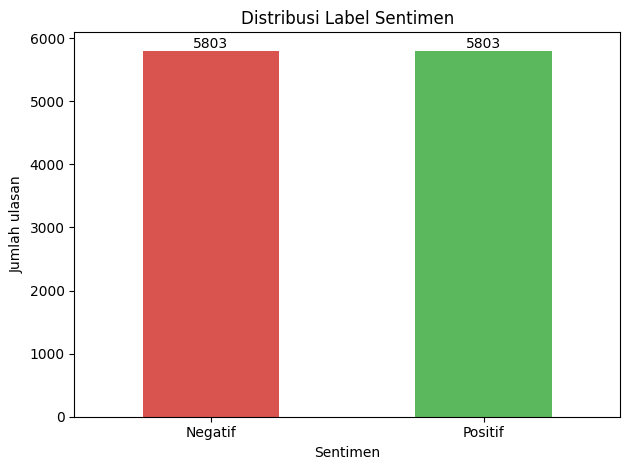

In [24]:
dist = df["sentimen"].value_counts().sort_index()
pct = (df["sentimen"].value_counts(normalize=True).sort_index() * 100).round(2)
label_map = {0: "Negatif", 1: "Positif"}
tabel = pd.DataFrame({"label": dist.index, "makna": [label_map[i] for i in dist.index], "jumlah": dist.values, "persen (%)": pct.values})
display(tabel)

ax = dist.rename(index=label_map).plot(kind="bar", color=["#d9534f", "#5cb85c"], rot=0)
ax.set_title("Distribusi Label Sentimen")
ax.set_xlabel("Sentimen"); ax.set_ylabel("Jumlah ulasan")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.savefig("distribusi_label.png", dpi=150); plt.show()

## 3. Preprocessing Teks

Kita bangun fungsi per tahap supaya hasil tiap tahap bisa dilihat. Urutan: **case folding → cleaning → tokenisasi → stopword removal → stemming**.

Catatan penting: daftar stopword Sastrawi memuat kata negasi seperti *tidak*. Untuk analisis sentimen, kata ini membawa makna ("tidak sesuai" ≠ "sesuai"), sehingga kita **pertahankan** kata negasi.

In [25]:
# --- 3.1 Case folding ---
def case_folding(text):
    return str(text).lower()

# --- 3.2 Cleaning ---
def cleaning(text):
    text = re.sub(r"http\S+|www\.\S+", " ", text)   # hapus URL
    text = re.sub(r"\d+", " ", text)                 # hapus angka
    text = re.sub(r"[^a-z\s]", " ", text)            # hapus tanda baca, emoji, karakter khusus
    text = re.sub(r"\s+", " ", text).strip()         # rapikan spasi
    return text

# --- 3.3 Tokenisasi ---
def tokenize(text):
    return text.split()

# --- 3.4 Stopword removal ---
NEGASI = {"tidak", "tak", "bukan", "belum", "jangan"}
stopwords = set(StopWordRemoverFactory().get_stop_words()) - NEGASI
print("Jumlah stopword dipakai:", len(stopwords))

def remove_stopwords(tokens):
    return [t for t in tokens if t not in stopwords]

# --- 3.5 Stemming (Sastrawi) + cache agar cepat ---
stemmer = StemmerFactory().create_stemmer()
_stem_cache = {}
def stem_tokens(tokens):
    out = []
    for t in tokens:
        if t not in _stem_cache:
            _stem_cache[t] = stemmer.stem(t)
        out.append(_stem_cache[t])
    return out

Jumlah stopword dipakai: 121


In [26]:
# Demo satu kalimat, tahap demi tahap
contoh = "Barang TIDAK sesuai gambar!!! Kecewa banget :( cek https://shopee.co.id/abc 100%"
a = case_folding(contoh);        print("1. Case folding :", a)
b = cleaning(a);                 print("2. Cleaning     :", b)
c = tokenize(b);                 print("3. Tokenisasi   :", c)
d = remove_stopwords(c);         print("4. Stopword     :", d)
e = stem_tokens(d);              print("5. Stemming     :", e)

1. Case folding : barang tidak sesuai gambar!!! kecewa banget :( cek https://shopee.co.id/abc 100%
2. Cleaning     : barang tidak sesuai gambar kecewa banget cek
3. Tokenisasi   : ['barang', 'tidak', 'sesuai', 'gambar', 'kecewa', 'banget', 'cek']
4. Stopword     : ['barang', 'tidak', 'sesuai', 'gambar', 'kecewa', 'banget', 'cek']
5. Stemming     : ['barang', 'tidak', 'sesuai', 'gambar', 'kecewa', 'banget', 'cek']


In [10]:
# Terapkan ke seluruh dataset (kolom review asli tidak diubah)
df["case_folding"] = df["review"].apply(case_folding)
df["cleaning"]     = df["case_folding"].apply(cleaning)
df["tokens"]       = df["cleaning"].apply(tokenize)
df["no_stopword"]  = df["tokens"].apply(remove_stopwords)
df["stemmed"]      = df["no_stopword"].apply(stem_tokens)
df["clean_text"]   = df["stemmed"].apply(lambda t: " ".join(t))
df[["review", "clean_text"]].head()

,review,clean_text
0,Suara dan mic puas. Hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala,suara mic puas pesan yg nyala sy pasti lg klik yg nyala tp yg datang ga nyala
1,Good. Mudah-mudahan awet. Makasih,good mudah mudah awet makasih
2,"kondisi dus robek2, tolong di perhatikan lagi",kondisi dus robek perhati
3,Kualitas produk baik. Harga terjangkau dan pengirimannya cepet banget. Udh 3x order disini oke lah tp sayangnya klo ...,kualitas produk baik harga jangkau kirim cepet banget udh x order sini oke lah tp sayang klo buat kado gabisa nitip ...
4,"Overall bagus, tombol berfungsi semuanya, tapi packaging kurang karena sudah penyot dan robek sedikit",overall bagus tombol fungsi semua packaging kurang penyot robek sedikit


## 4. Sepuluh Contoh Sebelum dan Sesudah Preprocessing

In [11]:
sampel = df.sample(10, random_state=42)[["review", "clean_text", "sentimen"]].reset_index(drop=True)
sampel.index = sampel.index + 1
sampel.columns = ["Sebelum (review asli)", "Sesudah (clean_text)", "Label"]
display(sampel)

,Sebelum (review asli),Sesudah (clean_text),Label
1,Barangnya original 👍. Bisa muat banyak. Gampang dipakai. Penjualnya kurang ramah,barang original muat banyak gampang pakai jual kurang ramah,0
2,Barang sudah sampai pengirimannya cepat,barang kirim cepat,1
3,"realpict, packing oke",realpict packing oke,1
4,Cuman bisa komen 👍👍👍,cuman komen,0
5,"mantap banget, pengiriman cepat pesan sekarang besok sudah ditangan.Desain elegan 😍. Resolusi gambar tajam 👍.",mantap banget kirim cepat pesan sekarang besok tang desain elegan resolusi gambar tajam,1
6,"awalnya dikrm hanya unit saja, setelah komplain baru dikrm dan info bonus bundling harusnya diupdate kalo tumbler da...",awal dikrm unit komplain baru dikrm info bonus bundling harus diupdate kalo tumbler dah habis jadi tidak buat langga...,0
7,"menurut infonya free Mola TV tp ternyata perlu bayar, setelah diskusi panjang akhirnya diketahui kalau OS nya tidak ...",info free mola tv tp nyata perlu bayar diskusi panjang akhir tahu kalau os nya tidak diupdate beli belum hari sejak ...,0
8,Pesanan sesuai cuma syang nya gak ada saringanya buat mengkukus lain kali lebih teliti lgi ya,pesan sesuai cuma syang nya gak saringanya buat kukus kali lebih teliti lgi,0
9,remote control tidak peka,remote control tidak peka,0
10,Sudah sampai mesin cuci nya terima kasih cepat ya 5 hari sampai...kerennn,mesin cuci nya terima kasih cepat hari kerennn,1


In [12]:
# Simpan ke CSV untuk dilampirkan di laporan
sampel.to_csv("contoh_10_sebelum_sesudah.csv", index_label="No")

## 5. Pengaruh Preprocessing terhadap Kualitas Data Teks

In [13]:
# Bandingkan sebelum vs sesudah secara kuantitatif
sebelum_tokens = df["review"].str.split()
sesudah_tokens = df["stemmed"]

vocab_sebelum = set(t for toks in sebelum_tokens for t in toks)
vocab_sesudah = set(t for toks in sesudah_tokens for t in toks)

stat = pd.DataFrame({
    "Sebelum": [df["review"].str.len().mean(), sebelum_tokens.apply(len).mean(), len(vocab_sebelum)],
    "Sesudah": [df["clean_text"].str.len().mean(), sesudah_tokens.apply(len).mean(), len(vocab_sesudah)],
}, index=["Rata-rata panjang karakter", "Rata-rata jumlah kata", "Ukuran vocabulary (kata unik)"]).round(2)
stat["Perubahan (%)"] = ((stat["Sesudah"] - stat["Sebelum"]) / stat["Sebelum"] * 100).round(2)
display(stat)

kosong = (df["clean_text"].str.strip() == "").sum()
print("Ulasan yang menjadi kosong setelah preprocessing:", kosong)
stat.to_csv("statistik_preprocessing.csv")

,Sebelum,Sesudah,Perubahan (%)
Rata-rata panjang karakter,103.57,79.00,-23.72
Rata-rata jumlah kata,15.76,13.21,-16.18
Ukuran vocabulary (kata unik),26205.00,10161.00,-61.22


Ulasan yang menjadi kosong setelah preprocessing: 5


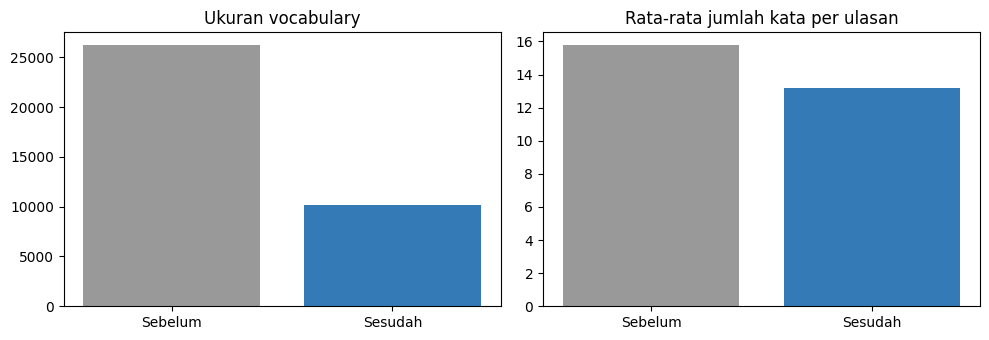

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
labels = ["Sebelum", "Sesudah"]
ax[0].bar(labels, [stat.loc["Ukuran vocabulary (kata unik)", "Sebelum"], stat.loc["Ukuran vocabulary (kata unik)", "Sesudah"]], color=["#999", "#337ab7"])
ax[0].set_title("Ukuran vocabulary")
ax[1].bar(labels, [stat.loc["Rata-rata jumlah kata", "Sebelum"], stat.loc["Rata-rata jumlah kata", "Sesudah"]], color=["#999", "#337ab7"])
ax[1].set_title("Rata-rata jumlah kata per ulasan")
plt.tight_layout(); plt.savefig("perbandingan_statistik.png", dpi=150); plt.show()

In [15]:
# Kata paling sering muncul setelah preprocessing
from collections import Counter
cnt = Counter(t for toks in df["stemmed"] for t in toks)
top = pd.DataFrame(cnt.most_common(15), columns=["kata", "frekuensi"])
display(top)

,kata,frekuensi
0,barang,4730
1,kirim,4155
2,bagus,3036
3,nya,2790
4,baik,2678
5,cepat,1757
6,lama,1748
7,sesuai,1684
8,yg,1648
9,tidak,1435


### Penjelasan singkat

*(Isi dengan angka dari tabel di atas setelah notebook dijalankan.)*

- **Case folding** menyamakan "Bagus", "BAGUS", dan "bagus" menjadi satu kata sehingga vocabulary tidak membengkak.
- **Cleaning** membuang URL, angka, tanda baca, dan emoji yang tidak membawa makna sentimen, sehingga noise berkurang.
- **Tokenisasi** memecah kalimat menjadi unit kata agar bisa diproses (dihitung, difilter, di-stem) satu per satu.
- **Stopword removal** menghapus kata umum ("yang", "dan", "di") yang frekuensinya tinggi tetapi kurang informatif. Kata negasi (*tidak*, *bukan*) sengaja dipertahankan karena membalik makna sentimen.
- **Stemming** mengubah kata berimbuhan ke bentuk dasar ("pengiriman" → "kirim") sehingga variasi kata digabung dan vocabulary mengecil.

**Dampak keseluruhan:** teks menjadi lebih ringkas dan seragam, ukuran vocabulary turun, dan fitur yang tersisa lebih terfokus pada kata bermakna. Hal ini umumnya membantu model klasifikasi sentimen. **Kekurangannya:** stemming bisa terlalu agresif (mis. "beranta" dari "berantakan"), dan ulasan sangat pendek bisa kehilangan konteks atau menjadi kosong.

## 6. Membuat Laporan PDF Otomatis

Sel di bawah menyusun laporan PDF dari hasil yang baru saja dihitung. **Isi `GITHUB_URL` dengan link repositori GitHub-mu**, lalu jalankan.

In [16]:
GITHUB_URL = "https://github.com/amalulazhari896-cyber/preprocessing-ulasan-ecommerce"   # <-- GANTI dengan link repo GitHub-mu
NAMA, NIM = "Amalul Azhari", "24146078"

from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import cm
from reportlab.lib import colors
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image, PageBreak
from xml.sax.saxutils import escape

ss = getSampleStyleSheet()
H1 = ParagraphStyle("H1", parent=ss["Heading1"], fontSize=15, spaceAfter=6)
H2 = ParagraphStyle("H2", parent=ss["Heading2"], fontSize=12, spaceBefore=10, spaceAfter=4)
BODY = ParagraphStyle("B", parent=ss["BodyText"], fontSize=10, leading=14, alignment=4)
SMALL = ParagraphStyle("S", parent=ss["BodyText"], fontSize=7.5, leading=9.5)
SMALLB = ParagraphStyle("SB", parent=SMALL, fontName="Helvetica-Bold")
P = lambda t, st=BODY: Paragraph(t, st)

def tbl(data, widths, header=True, fs=8.5):
    t = Table(data, colWidths=widths, repeatRows=1 if header else 0)
    st = [("GRID", (0,0), (-1,-1), 0.4, colors.grey), ("VALIGN", (0,0), (-1,-1), "TOP"), ("FONTSIZE", (0,0), (-1,-1), fs)]
    if header: st += [("BACKGROUND", (0,0), (-1,0), colors.HexColor("#e8eef7")), ("FONTNAME", (0,0), (-1,0), "Helvetica-Bold")]
    t.setStyle(TableStyle(st)); return t

ORIG_COLS = [c for c in ["review", "translate", "sentimen"] if c in df.columns]
n_data, n_kol = len(df), len(ORIG_COLS)
n_neg, n_pos = int(dist.get(0, 0)), int(dist.get(1, 0))
v_b, v_a = int(stat.loc["Ukuran vocabulary (kata unik)", "Sebelum"]), int(stat.loc["Ukuran vocabulary (kata unik)", "Sesudah"])
w_b, w_a = stat.loc["Rata-rata jumlah kata", "Sebelum"], stat.loc["Rata-rata jumlah kata", "Sesudah"]
c_b, c_a = stat.loc["Rata-rata panjang karakter", "Sebelum"], stat.loc["Rata-rata panjang karakter", "Sesudah"]
turun_v = (v_b - v_a) / v_b * 100
turun_w = (w_b - w_a) / w_b * 100

E = []
E += [P("Laporan Tugas Preprocessing Teks", H1),
      P("<b>Ulasan E-Commerce Berbahasa Indonesia</b>"),
      Spacer(1, 4),
      P(f"Nama: <b>{NAMA}</b><br/>NIM: <b>{NIM}</b><br/>Dataset: dipawidia/ecommerce-product-reviews-sentiment (Hugging Face)<br/>GitHub: <link href='{GITHUB_URL}' color='blue'>{GITHUB_URL}</link>")]

E += [P("1. Informasi Dataset", H2),
      P(f"Dataset berisi <b>{n_data:,}</b> ulasan produk berbahasa Indonesia dengan <b>{n_kol}</b> kolom: " + ", ".join(f"<i>{c}</i>" for c in ORIG_COLS) + ". Kolom <i>review</i> adalah teks ulasan, <i>translate</i> adalah terjemahan Inggris, dan <i>sentimen</i> adalah label (0 = negatif, 1 = positif). "
        f"Jumlah missing value pada kolom review: {int(df['review'].isna().sum())}; ulasan duplikat: {int(df['review'].duplicated().sum())}.")]
dt = [["Label", "Makna", "Jumlah", "Persentase"]] + [[str(r.label), r.makna, f"{r.jumlah:,}", f"{r._4:.2f}%"] for r in tabel.rename(columns={"persen (%)": "_4"}).itertuples()]
E += [Spacer(1, 4), tbl(dt, [2*cm, 4*cm, 3*cm, 3*cm]), Spacer(1, 6), Image("distribusi_label.png", width=11*cm, height=11*cm*0.75)]

E += [P("2. Tahapan Preprocessing", H2),
      P("Tahapan dilakukan berurutan: (1) <b>case folding</b>, mengubah teks menjadi huruf kecil; (2) <b>cleaning</b>, menghapus URL, angka, tanda baca, emoji, dan karakter khusus menggunakan regular expression; "
        "(3) <b>tokenisasi</b>, memisahkan teks menjadi kata; (4) <b>stopword removal</b>, menghapus kata tidak penting memakai daftar stopword Sastrawi, dengan mempertahankan kata negasi (tidak, tak, bukan, belum, jangan) karena membalik makna sentimen; "
        "(5) <b>stemming</b>, mengubah kata ke bentuk dasar memakai Sastrawi. Seluruh kode tersedia di notebook pada repositori GitHub.")]

E += [P("3. Sepuluh Contoh Sebelum dan Sesudah Preprocessing", H2)]
rows = [[P("No", SMALLB), P("Sebelum", SMALLB), P("Sesudah", SMALLB), P("Label", SMALLB)]]
for i, r in sampel.iterrows():
    rows.append([P(str(i), SMALL), P(escape(str(r.iloc[0])[:400]), SMALL), P(escape(str(r.iloc[1])) or "(kosong)", SMALL), P(str(r.iloc[2]), SMALL)])
E += [tbl(rows, [0.9*cm, 7.4*cm, 7.4*cm, 1.3*cm])]

E += [PageBreak(), P("4. Pengaruh Preprocessing terhadap Kualitas Data Teks", H2)]
st_rows = [["Ukuran", "Sebelum", "Sesudah", "Perubahan"]] + [[i, f"{r['Sebelum']:,.2f}", f"{r['Sesudah']:,.2f}", f"{r['Perubahan (%)']:.2f}%"] for i, r in stat.iterrows()]
E += [tbl(st_rows, [6.5*cm, 3.2*cm, 3.2*cm, 3.2*cm]), Spacer(1, 6), Image("perbandingan_statistik.png", width=14*cm, height=14*cm*0.35), Spacer(1, 6)]
E += [P(f"Setelah preprocessing, ukuran vocabulary turun dari <b>{v_b:,}</b> menjadi <b>{v_a:,}</b> kata unik (berkurang {turun_v:.1f}%), dan rata-rata jumlah kata per ulasan turun dari {w_b:.2f} menjadi {w_a:.2f} (berkurang {turun_w:.1f}%). "
          "Penurunan vocabulary terutama berasal dari case folding (variasi huruf besar/kecil menyatu), cleaning (URL, angka, dan simbol hilang), serta stemming (kata berimbuhan seperti <i>pengiriman</i> dan <i>dikirim</i> digabung menjadi <i>kirim</i>)."),
      Spacer(1, 4),
      P("Dampak positif: teks menjadi lebih seragam dan bersih dari noise, dimensi fitur lebih kecil sehingga komputasi lebih ringan, dan kata yang tersisa lebih berfokus pada makna yang berkaitan dengan sentimen. "
        "Hal ini membantu model klasifikasi mempelajari pola dengan lebih stabil dan mengurangi risiko overfitting pada kata yang jarang muncul."),
      Spacer(1, 4),
      P(f"Keterbatasan: stemming dapat terlalu agresif sehingga menghasilkan bentuk yang kurang tepat (mis. <i>berantakan</i> menjadi <i>beranta</i>), kata tidak baku atau singkatan (mis. <i>bgt</i>, <i>mantul</i>) tidak ditangani karena tidak ada normalisasi slang, "
        f"dan penghapusan stopword atau karakter dapat menghilangkan konteks pada ulasan yang sangat pendek. Jumlah ulasan yang menjadi kosong setelah preprocessing: <b>{int(kosong)}</b>."),
      P("5. Kesimpulan", H2),
      P("Preprocessing berhasil mengubah teks ulasan mentah menjadi teks yang lebih bersih, ringkas, dan konsisten sehingga lebih siap digunakan pada tahap ekstraksi fitur dan pemodelan analisis sentimen.")]

SimpleDocTemplate("Laporan_Preprocessing_Teks_24146078.pdf", pagesize=A4, leftMargin=2*cm, rightMargin=2*cm, topMargin=2*cm, bottomMargin=2*cm,
                  title="Laporan Preprocessing Teks", author=NAMA).build(E)
print("Laporan dibuat: Laporan_Preprocessing_Teks_24146078.pdf")
try:
    from google.colab import files
    files.download("Laporan_Preprocessing_Teks_24146078.pdf")
except Exception:
    pass

Laporan dibuat: Laporan_Preprocessing_Teks_24146078.pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
# Simpan hasil akhir
df[["review", "clean_text", "sentimen"]].to_csv("hasil_preprocessing.csv", index=False)